# FarmResilience Analytics: Agricultural Production Trends, Crop Productivity and Resilience in Kenya

## 1. Project Objective

This notebook examines historical agricultural production, harvested area, and yield for five selected crops in Kenya from 1961 to 2024 using FAOSTAT data.

The analysis aims to:

- Examine long-term crop production trends.
- Compare changes in harvested area and yield.
- Assess year-to-year production variability.
- Identify patterns that may inform agricultural planning and resilience-related decisions.

## 2. Selected Crops

- Maize (corn)
- Beans, dry
- Sorghum
- Millet
- Cassava, fresh

## 3. Data Source

FAOSTAT — Crops and Livestock Products (Production).

## 4. Analytical Limitations

The dataset contains national-level agricultural statistics rather than individual farmer records. Production variability is treated as a descriptive indicator of output stability, not a comprehensive measure of farmer resilience.

Observed changes do not, by themselves, establish the causes of production changes or demonstrate the effects of agricultural interventions.


Step 1 — Load and prepare the data

In [1]:

import pandas as pd
import zipfile
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Locate the source data
zip_path = Path("Production_Crops_Livestock_E_Africa.zip")

if not zip_path.exists():
    raise FileNotFoundError(
        "Place the FAOSTAT ZIP file in the notebook's working directory."
    )

# Load the numerical dataset
with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open(
        "Production_Crops_Livestock_E_Africa_NOFLAG.csv"
    ) as file:
        df = pd.read_csv(file, low_memory=False)

# Identify annual value columns
year_cols = [
    col for col in df.columns
    if col.startswith("Y") and col[1:].isdigit()
]

id_cols = [col for col in df.columns if col not in year_cols]

# Reshape to long format
df_long = df.melt(
    id_vars=id_cols,
    value_vars=year_cols,
    var_name="Year",
    value_name="Value"
)

df_long["Year"] = (
    df_long["Year"]
    .str.replace("Y", "", regex=False)
    .astype(int)
)

df_long["Value"] = pd.to_numeric(
    df_long["Value"], errors="coerce"
)

# Define the analytical scope
selected_crops = [
    "Maize (corn)",
    "Beans, dry",
    "Sorghum",
    "Millet",
    "Cassava, fresh"
]

selected_elements = [
    "Production",
    "Area harvested",
    "Yield"
]

df_crop = df_long[
    (df_long["Area"] == "Kenya")
    & (df_long["Item"].isin(selected_crops))
    & (df_long["Element"].isin(selected_elements))
].copy()

# Inspect the prepared dataset
print("Full dataset shape:", df_long.shape)
print("Analytical dataset shape:", df_crop.shape)
print("Year range:", df_crop["Year"].min(), "-", df_crop["Year"].max())
print("Selected crops:", sorted(df_crop["Item"].unique()))
print("\nRecords by measure:")
display(df_crop.groupby("Element").size().rename("Records").to_frame())


Full dataset shape: (944000, 11)
Analytical dataset shape: (960, 11)
Year range: 1961 - 2024
Selected crops: ['Beans, dry', 'Cassava, fresh', 'Maize (corn)', 'Millet', 'Sorghum']

Records by measure:


,Records
Element,
Area harvested,320
Production,320
Yield,320


Step 2 — Analyze long-term production trends
##Long-Term Crop Production Trends
This section examines how annual production has changed across the five selected crops between 1961 and 2024. We will compare absolute production volumes and indexed trends to understand both the scale of production and relative changes over time.
Production trends alone do not identify the causes of change or establish improvements in farmer welfare.


Step 2.1 — Plot annual production

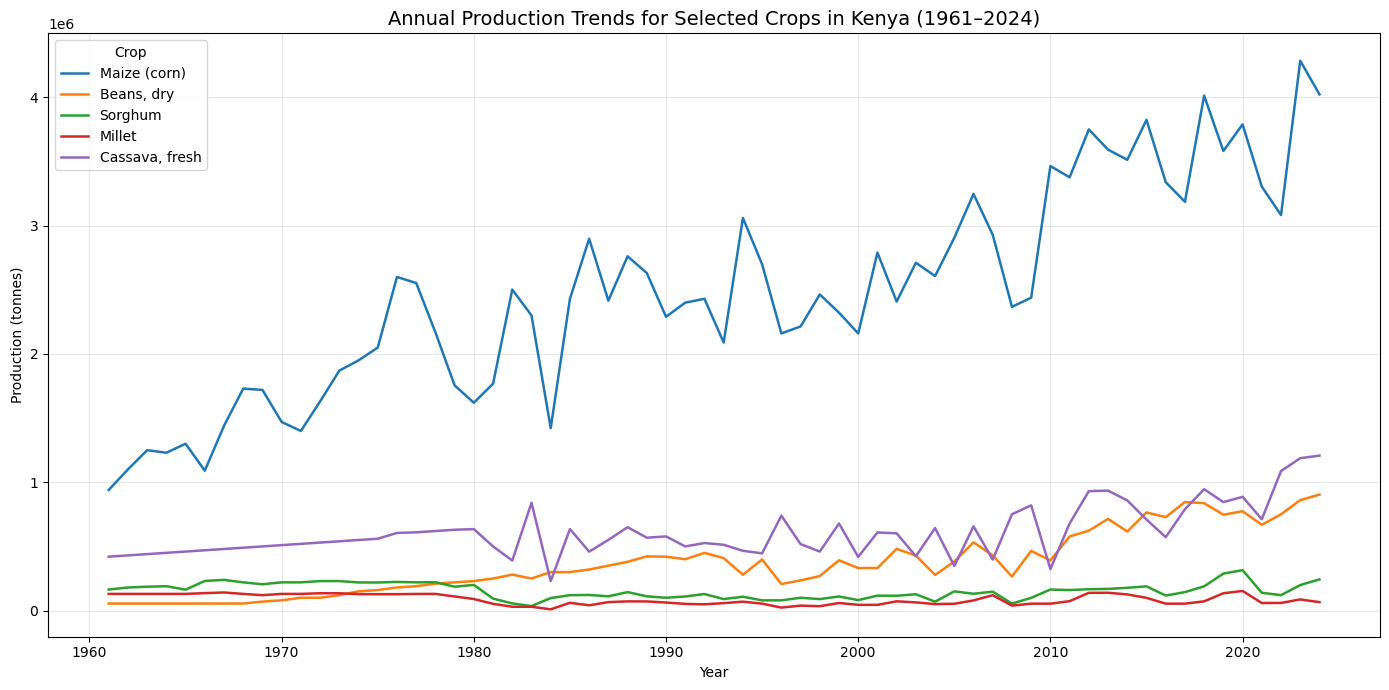

In [2]:

# Filter production observations
production_df = df_crop[
    df_crop["Element"] == "Production"
].copy()

# Plot annual production for each selected crop
plt.figure(figsize=(14, 7))

for crop in selected_crops:
    crop_data = production_df[
        production_df["Item"] == crop
    ].sort_values("Year")

    plt.plot(
        crop_data["Year"],
        crop_data["Value"],
        label=crop,
        linewidth=1.8
    )

plt.title(
    "Annual Production Trends for Selected Crops in Kenya (1961–2024)",
    fontsize=14
)
plt.xlabel("Year")
plt.ylabel("Production (tonnes)")
plt.legend(title="Crop")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
Step 4.2 — Create an indexed trend comparison
To compare relative growth more fairly, we can set each crop's 1961 production equal to an index of 100. An index of 200 means production is twice its 1961 level; an index of 50 means it is half its baseline.

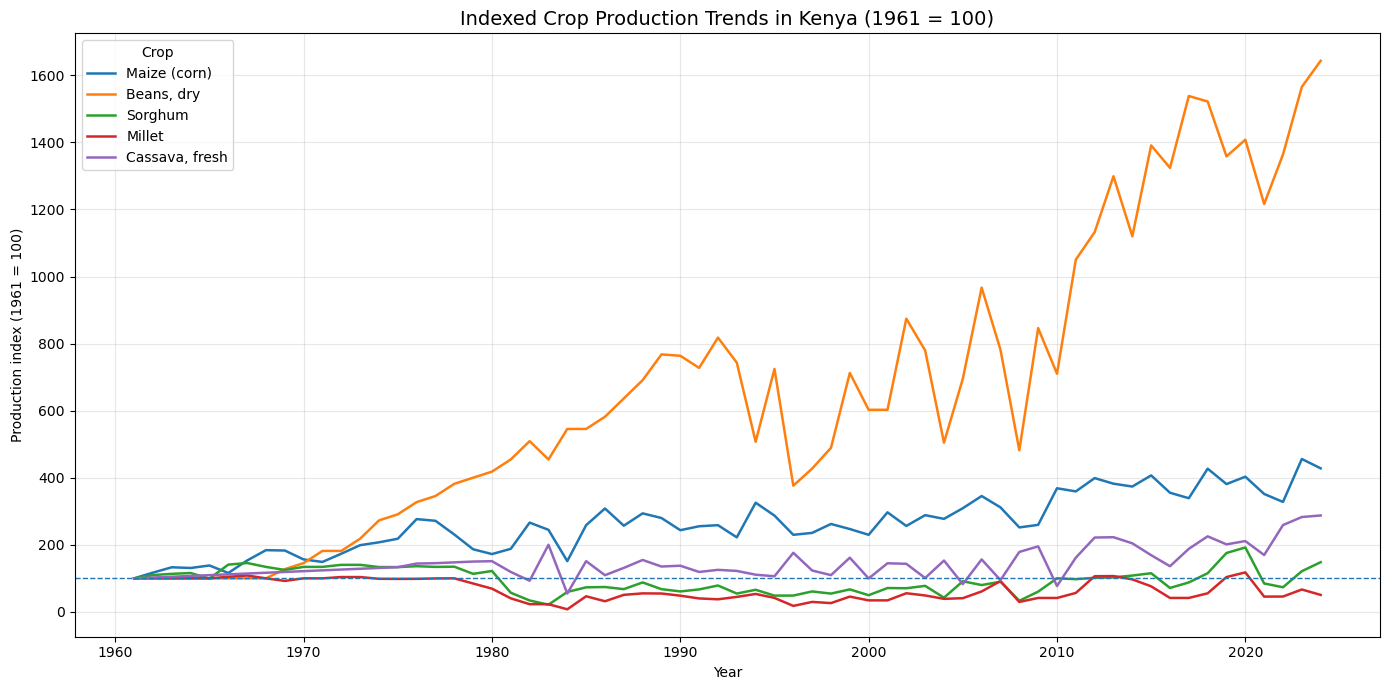

In [3]:

# Sort observations and obtain each crop's 1961 baseline
production_df = production_df.sort_values(["Item", "Year"]).copy()

baseline_1961 = (
    production_df.loc[production_df["Year"] == 1961]
    .set_index("Item")["Value"]
)

# Calculate indexed production, with 1961 = 100
production_df["Production_Index_1961_100"] = (
    production_df["Value"]
    / production_df["Item"].map(baseline_1961)
    * 100
)

# Plot indexed trends
plt.figure(figsize=(14, 7))

for crop in selected_crops:
    crop_data = production_df[
        production_df["Item"] == crop
    ].sort_values("Year")

    plt.plot(
        crop_data["Year"],
        crop_data["Production_Index_1961_100"],
        label=crop,
        linewidth=1.8
    )

plt.axhline(100, linestyle="--", linewidth=1)
plt.title(
    "Indexed Crop Production Trends in Kenya (1961 = 100)",
    fontsize=14
)
plt.xlabel("Year")
plt.ylabel("Production index (1961 = 100)")
plt.legend(title="Crop")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Interpretation of Long-Term Production Trends

The absolute production chart shows that maize (corn) has the largest production volume among the five selected crops. However, absolute production alone does not indicate productivity, efficiency, or resilience.

The indexed production chart highlights a different pattern: dry beans show stronger relative growth from the 1961 baseline. In the endpoint comparison, dry bean production increased from 55,000 tonnes in 1961 to approximately 903,851 tonnes in 2024, while maize production increased from 940,000 to 4,023,000 tonnes.

These results demonstrate the importance of distinguishing production scale from relative growth. Indexed trends allow comparisons across crops with different starting production volumes, although they remain sensitive to the choice of baseline year.

The observed changes do not establish the causes of production growth or demonstrate changes in farmer welfare.


### Step 3 — Compare harvested area and yield
Production can change because the area harvested changes, yield changes, or both. These two charts will help us distinguish those patterns descriptively.

### 3.1 Plot harvested area over time

What to examine: Which crops have expanded their harvested area? Has that expansion been steady, or are there noticeable fluctuations?

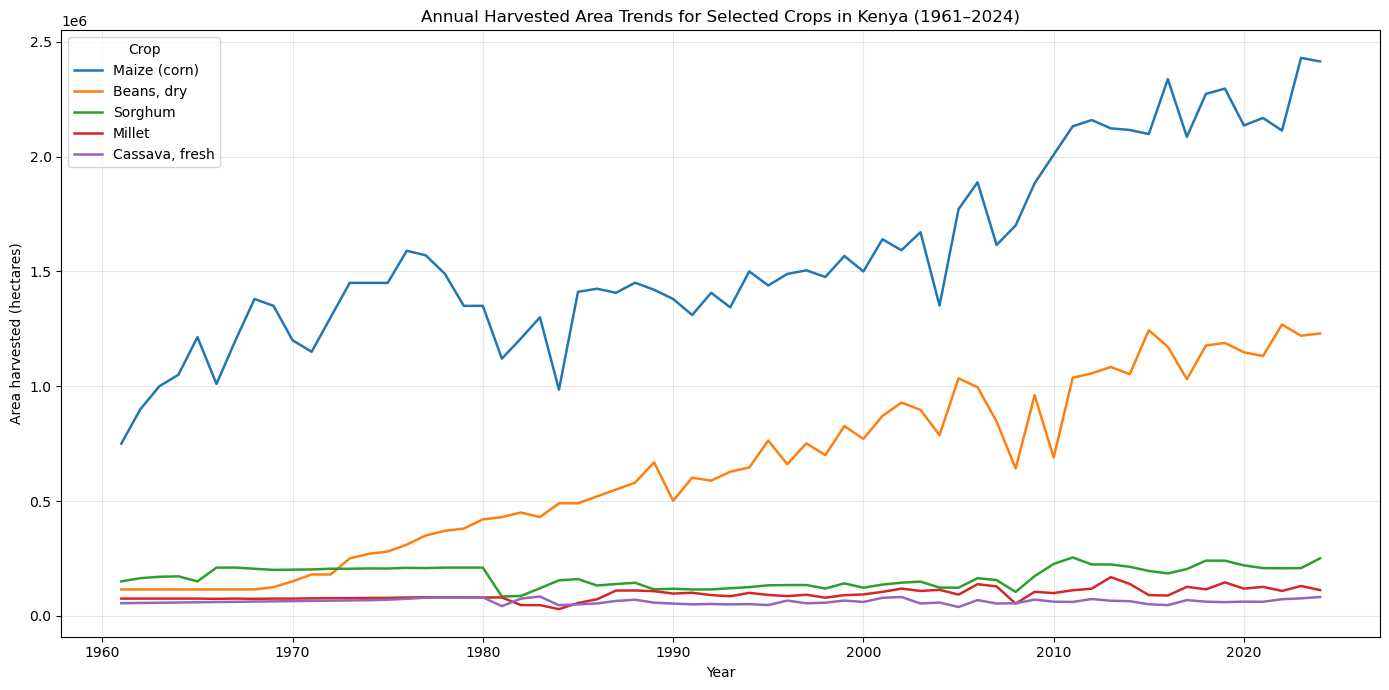

In [4]:
# Step 3.1: Harvested area trends

area_df = df_crop[df_crop["Element"] == "Area harvested"].copy()

plt.figure(figsize=(14, 7))

for crop in selected_crops:
    crop_data = area_df[area_df["Item"] == crop].sort_values("Year")
    plt.plot(
        crop_data["Year"],
        crop_data["Value"],
        label=crop,
        linewidth=1.8
    )

plt.title("Annual Harvested Area Trends for Selected Crops in Kenya (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Area harvested (hectares)")
plt.legend(title="Crop")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2 Plot yield over time
What to examine: Which crops show increasing or decreasing yields? Are there sharp fluctuations, and do the patterns resemble what you observed in production?

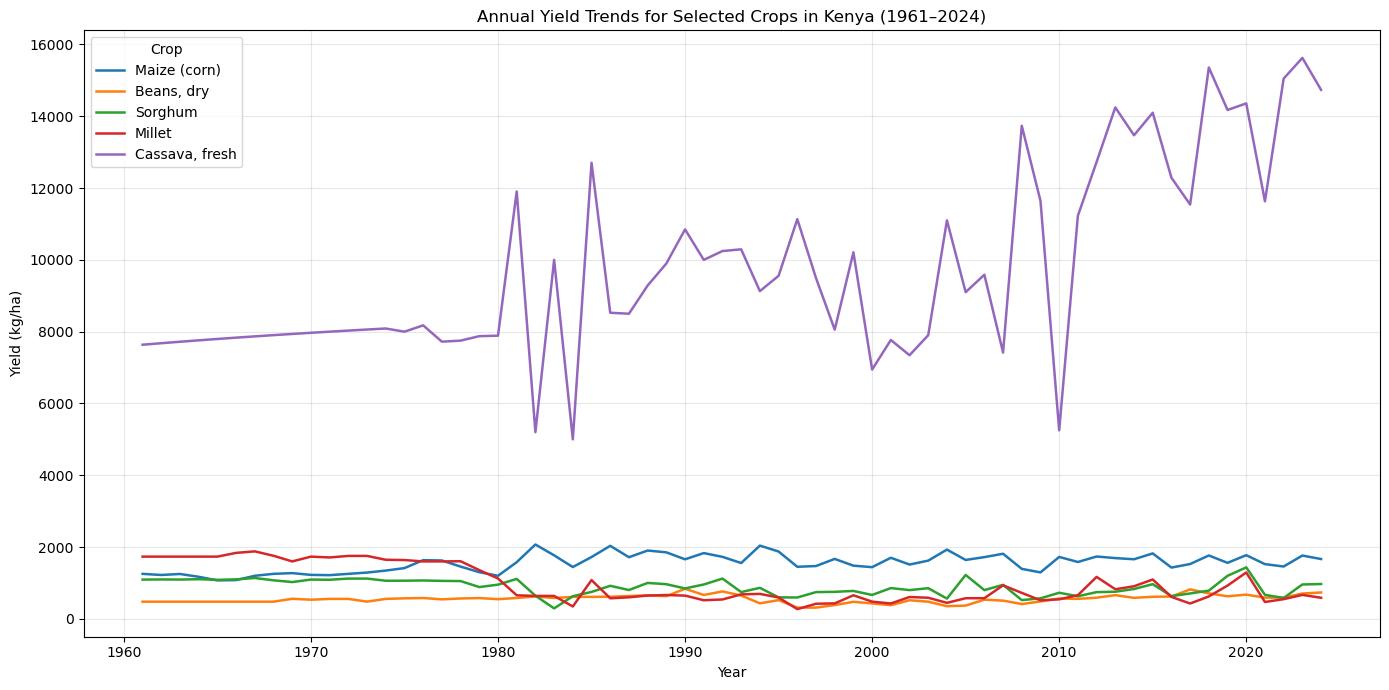

In [5]:
# Step 3.2: Yield trends

yield_df = df_crop[df_crop["Element"] == "Yield"].copy()

plt.figure(figsize=(14, 7))

for crop in selected_crops:
    crop_data = yield_df[yield_df["Item"] == crop].sort_values("Year")
    plt.plot(
        crop_data["Year"],
        crop_data["Value"],
        label=crop,
        linewidth=1.8
    )

plt.title("Annual Yield Trends for Selected Crops in Kenya (1961–2024)")
plt.xlabel("Year")
plt.ylabel("Yield (kg/ha)")
plt.legend(title="Crop")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 3.1 Harvested Area Trends

The harvested area chart shows that maize experienced the largest absolute increase in harvested land between 1961 and 2024, followed by dry beans. The remaining crops generally occupy smaller areas and appear closer together on the chart. Dry beans display a relatively steady upward trajectory, while maize shows substantial long-term expansion.

These patterns suggest that changes in the amount of land harvested may have contributed to the long-term growth in production for maize and dry beans. However, national-level data alone cannot establish why harvested area changed or whether the expansion occurred at the expense of other crops.

### 3.2 Yield Trends

The yield chart shows that cassava has the highest yield per hectare among the five selected crops, with substantial fluctuations over time. Millet experienced an initial decline followed by a comparatively flatter pattern. Sorghum shows a modest decline before stabilizing, while maize displays a modest increase followed by a relatively flatter trend. Dry bean yields appear comparatively stable.

These patterns indicate that productivity developments differ by crop. Cassava's higher yield values should be interpreted in the context of its crop characteristics; yield levels should not be compared as though different crops produce equivalent outputs per hectare. The flatter patterns also do not necessarily mean that yields remained unchanged in every year.

The analysis is descriptive. Additional data would be needed to determine the causes of these trends or their implications for farmer welfare and agricultural resilience.

### Step 3.4 — Quantify the changes
The charts help us see the patterns, but a portfolio project becomes stronger when the observations are supported by measurable results.
It calculates the percentage change in harvested area and yield between 1961 and 2024 for each crop.
What to look for
- Harvested area: Which crops expanded the most in percentage terms?
- Yield: Which crops achieved the largest percentage improvement, and which declined?
- Production versus yield: Did production growth coincide with yield improvement, expansion of harvested land, or both?

In [6]:
# Compare harvested area and yield at the beginning and end of the period

measures_to_compare = ["Area harvested", "Yield"]

comparison_rows = []

for element in measures_to_compare:
    measure_df = df_crop[df_crop["Element"] == element]

    for crop in selected_crops:
        crop_data = measure_df[measure_df["Item"] == crop]

        start_value = crop_data.loc[
            crop_data["Year"] == 1961, "Value"
        ].iloc[0]

        end_value = crop_data.loc[
            crop_data["Year"] == 2024, "Value"
        ].iloc[0]

        percentage_change = (
            (end_value - start_value) / start_value
        ) * 100

        comparison_rows.append({
            "Crop": crop,
            "Measure": element,
            "Value_1961": start_value,
            "Value_2024": end_value,
            "Absolute_Change": end_value - start_value,
            "Percentage_Change": percentage_change
        })

area_yield_comparison = pd.DataFrame(comparison_rows)

area_yield_comparison[
    ["Value_1961", "Value_2024", "Absolute_Change", "Percentage_Change"]
] = area_yield_comparison[
    ["Value_1961", "Value_2024", "Absolute_Change", "Percentage_Change"]
].round(2)

display(
    area_yield_comparison.sort_values(
        ["Measure", "Percentage_Change"],
        ascending=[True, False]
    ).reset_index(drop=True)
)

,Crop,Measure,Value_1961,Value_2024,Absolute_Change,Percentage_Change
0,"Beans, dry",Area harvested,115000.0,1229882.0,1114882.0,969.46
1,Maize (corn),Area harvested,750000.0,2414536.0,1664536.0,221.94
2,Sorghum,Area harvested,150000.0,250432.0,100432.0,66.95
3,Millet,Area harvested,75000.0,112093.0,37093.0,49.46
4,"Cassava, fresh",Area harvested,55000.0,81944.0,26944.0,48.99
5,"Cassava, fresh",Yield,7636.4,14736.1,7099.7,92.97
6,"Beans, dry",Yield,478.3,734.9,256.6,53.65
7,Maize (corn),Yield,1253.3,1666.2,412.9,32.95
8,Sorghum,Yield,1093.3,970.3,-123.0,-11.25
9,Millet,Yield,1733.3,586.7,-1146.6,-66.15


Three findings stand out:
- Dry beans: Harvested area increased by 969.46%, while yield increased by 53.65%. This suggests that land expansion was a much larger relative change than yield improvement.
- Maize: Harvested area increased by 221.94%, and yield increased by 32.95%. Both measures rose, although the relative change was much larger for area.
- Cassava: Yield increased by 92.97%, the largest percentage increase among these five crops, while harvested area increased by only 48.99%.
- Millet: Harvested area increased by 49.46%, but yield declined by 66.15%. This is an important contrast because expanding harvested area did not prevent the decline in total production between the two endpoints.
- Sorghum: Harvested area increased by 66.95%, while yield declined by 11.25%.
These are descriptive comparisons, not proof that area expansion or yield changes caused a particular outcome. Also, percentage changes depend on the starting values, so we should avoid comparing percentages without considering the underlying quantities.

Step 4 — Measure year-to-year production variability
Now we move from long-term growth to stability over time. A crop may have higher production today but still experience substantial year-to-year fluctuations.
We’ll measure annual percentage changes in production and compare the standard deviation of those changes. A higher standard deviation indicates greater variability in annual percentage changes; it does not, by itself, measure overall agricultural resilience.

## Step4.1 Calculate annual production changes
### 4.1 Annual Production Variability
This section examines how much annual production changes from one year to the next for maize, dry beans, sorghum, millet and cassava in Kenya between 1961 and 2024.

Annual percentage changes provide a common scale for comparing crops of different production sizes. The standard deviation of annual percentage changes summarizes how widely these changes vary, while the mean absolute percentage change captures the average magnitude of annual movements regardless of direction.

These indicators measure production variability, not resilience in its entirety. They do not identify the causes of fluctuations or establish the effects on individual farmers.

In [7]:
# Calculate year-on-year percentage changes in crop production

production_df = df_crop[
    df_crop["Element"] == "Production"
].copy()

production_df = production_df.sort_values(
    ["Item", "Year"]
).copy()

production_df["Previous_Year_Production"] = (
    production_df.groupby("Item")["Value"].shift(1)
)

production_df["Annual_Change_Pct"] = (
    (
        production_df["Value"]
        - production_df["Previous_Year_Production"]
    )
    / production_df["Previous_Year_Production"]
) * 100

# Inspect the calculated changes
display(
    production_df[
        [
            "Item",
            "Year",
            "Value",
            "Previous_Year_Production",
            "Annual_Change_Pct"
        ]
    ].head(12).round(2)
)

,Item,Year,Value,Previous_Year_Production,Annual_Change_Pct
6329,"Beans, dry",1961,55000.0,NaN,NaN
21079,"Beans, dry",1962,55000.0,55000.0,0.00
35829,"Beans, dry",1963,55000.0,55000.0,0.00
50579,"Beans, dry",1964,55000.0,55000.0,0.00
65329,"Beans, dry",1965,55000.0,55000.0,0.00
80079,"Beans, dry",1966,55000.0,55000.0,0.00
94829,"Beans, dry",1967,55000.0,55000.0,0.00
109579,"Beans, dry",1968,55000.0,55000.0,0.00
124329,"Beans, dry",1969,70000.0,55000.0,27.27
139079,"Beans, dry",1970,80000.0,70000.0,14.29


4.2 Summarize variability by crop

In [8]:
# Summarize annual production variability

volatility_summary = (
    production_df
    .groupby("Item")["Annual_Change_Pct"]
    .agg(
        Years_Compared="count",
        Average_Annual_Change_Pct="mean",
        Volatility_Std_Pct="std",
        Median_Annual_Change_Pct="median"
    )
)

# Calculate the average absolute annual percentage change
mean_absolute_change = (
    production_df
    .groupby("Item")["Annual_Change_Pct"]
    .apply(lambda x: x.abs().mean())
    .rename("Mean_Absolute_Change_Pct")
)

volatility_summary = volatility_summary.join(
    mean_absolute_change
)

volatility_summary = volatility_summary.sort_values(
    "Volatility_Std_Pct",
    ascending=False
).round(2)

display(volatility_summary)

,Years_Compared,Average_Annual_Change_Pct,Volatility_Std_Pct,Median_Annual_Change_Pct,Mean_Absolute_Change_Pct
Item,,,,,
Millet,63,10.11,71.89,0.00,30.79
"Cassava, fresh",63,8.46,41.25,1.89,24.87
Sorghum,63,6.54,38.25,2.06,23.95
"Beans, dry",63,6.69,21.19,5.56,15.70
Maize (corn),63,3.95,19.10,-0.58,14.41


### 4.3 Visualize annual production variability

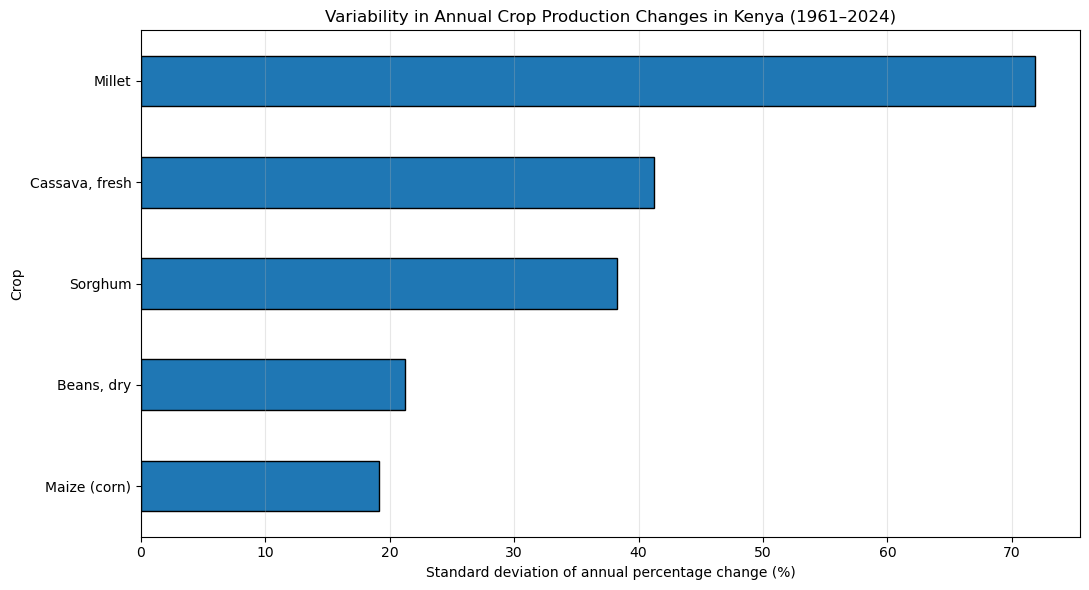

In [9]:
plt.figure(figsize=(11, 6))

volatility_summary["Volatility_Std_Pct"].sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title(
    "Variability in Annual Crop Production Changes in Kenya (1961–2024)"
)
plt.xlabel("Standard deviation of annual percentage change (%)")
plt.ylabel("Crop")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.4 Interpretation of Annual Production Variability

The variability analysis reveals substantial differences in year-to-year production changes across the five selected crops. Millet recorded the highest standard deviation of annual percentage changes (71.89%), followed by cassava (41.25%) and sorghum (38.25%). Dry beans (21.19%) and maize (19.10%) recorded lower variability.

Millet's high variability is consistent with the large historical production fluctuations identified earlier. Cassava and sorghum also experienced comparatively substantial annual changes. In contrast, maize and dry beans displayed lower variability according to this measure.

These findings can help identify crops for further investigation when assessing agricultural production stability. However, lower variability does not automatically imply greater resilience, food security or better outcomes for farmers. The results describe national production patterns and do not establish the causes of the fluctuations.

The average annual percentage change should also be interpreted cautiously. It is an arithmetic average of year-on-year changes, not a compound annual growth rate. Large percentage changes, particularly when previous-year production is low, can influence this average substantially.

### Step 5 — Identify the largest annual production shocks
Next, let's identify the years in which each crop experienced its largest increases and decreases. This will help us connect the variability summary to specific historical observations.

In [10]:
# Identify the five largest increases and five largest decreases
# in annual production percentage change.

valid_changes = production_df.dropna(
    subset=["Annual_Change_Pct"]
).copy()

largest_increases = (
    valid_changes
    .sort_values("Annual_Change_Pct", ascending=False)
    .groupby("Item")
    .head(3)
)

largest_decreases = (
    valid_changes
    .sort_values("Annual_Change_Pct", ascending=True)
    .groupby("Item")
    .head(3)
)

print("Largest annual production increases by crop:")
display(
    largest_increases[
        ["Item", "Year", "Previous_Year_Production",
         "Value", "Annual_Change_Pct"]
    ]
    .sort_values(["Item", "Annual_Change_Pct"],
                 ascending=[True, False])
    .round(2)
    .reset_index(drop=True)
)

print("Largest annual production decreases by crop:")
display(
    largest_decreases[
        ["Item", "Year", "Previous_Year_Production",
         "Value", "Annual_Change_Pct"]
    ]
    .sort_values(["Item", "Annual_Change_Pct"])
    .round(2)
    .reset_index(drop=True)
)

Largest annual production increases by crop:


,Item,Year,Previous_Year_Production,Value,Annual_Change_Pct
0,"Beans, dry",2009,265006.0,465363.0,75.60
1,"Beans, dry",2011,390598.0,577674.0,47.89
2,"Beans, dry",1999,269065.0,391825.0,45.62
3,"Cassava, fresh",1985,230000.0,635245.0,176.19
4,"Cassava, fresh",1983,390000.0,840000.0,115.38
5,"Cassava, fresh",2011,323389.0,679167.0,110.02
6,Maize (corn),1985,1422000.0,2430000.0,70.89
7,Maize (corn),1994,2089000.0,3060000.0,46.48
8,Maize (corn),2010,2439000.0,3464541.0,42.05
9,Millet,1985,10000.0,60480.0,504.80


Largest annual production decreases by crop:


,Item,Year,Previous_Year_Production,Value,Annual_Change_Pct
0,"Beans, dry",1996,398361.0,207000.0,-48.04
1,"Beans, dry",2008,429839.0,265006.0,-38.35
2,"Beans, dry",2004,428796.0,277501.0,-35.28
3,"Cassava, fresh",1984,840000.0,230000.0,-72.62
4,"Cassava, fresh",2010,819967.0,323389.0,-60.56
5,"Cassava, fresh",2005,642868.0,347819.0,-45.90
6,Maize (corn),1984,2300000.0,1422000.0,-38.17
7,Maize (corn),1996,2698863.0,2160000.0,-19.97
8,Maize (corn),2008,2928793.0,2367237.0,-19.17
9,Millet,2008,119599.0,38462.0,-67.84


Crop	Largest decline shown	Year	Production change
Cassava	−72.62%	1984	840,000 → 230,000 tonnes
Millet	−67.84%	2008	119,599 → 38,462 tonnes
Sorghum	−63.14%	2008	147,365 → 54,316 tonnes
Dry beans	−48.04%	1996	398,361 → 207,000 tonnes
Maize	−38.17%	1984	2,300,000 → 1,422,000 tonnes
A few observations worth documenting:
- 1984: Cassava and maize both recorded major production declines.
- 2008: Several crops experienced substantial declines, including millet, sorghum, cassava, maize and dry beans.
- 2021: Millet and sorghum both recorded large declines, making this another useful year to investigate.
- Crop-specific fluctuations: The largest declines occurred in different years for different crops, so we should not assume every crop responds identically to the same conditions.
These are national production figures. We cannot attribute the declines to drought, conflict, policy changes, pests or other causes without additional evidence.

In [11]:
# Investigate production, harvested area and yield
# around selected years with large production declines.

years_to_investigate = [1983, 1984, 1985, 2007, 2008, 2009, 2020, 2021, 2022]

shock_years_df = df_crop[
    df_crop["Year"].isin(years_to_investigate)
].copy()

shock_pivot = shock_years_df.pivot_table(
    index=["Item", "Year"],
    columns="Element",
    values="Value",
    aggfunc="first"
).reset_index()

shock_pivot = shock_pivot.rename(columns={
    "Area harvested": "Area_Harvested_ha",
    "Production": "Production_tonnes",
    "Yield": "Yield_kg_ha"
})

display(
    shock_pivot.sort_values(["Item", "Year"]).round(2)
)

Element,Item,Year,Area_Harvested_ha,Production_tonnes,Yield_kg_ha
0,"Beans, dry",1983,430000.0,250000.00,581.4
1,"Beans, dry",1984,490000.0,300000.00,612.2
2,"Beans, dry",1985,490000.0,300000.00,612.2
3,"Beans, dry",2007,846327.0,429839.00,507.9
4,"Beans, dry",2008,641936.0,265006.00,412.8
5,"Beans, dry",2009,960705.0,465363.00,484.4
6,"Beans, dry",2020,1147709.0,774365.67,674.7
7,"Beans, dry",2021,1131565.0,668916.00,591.1
8,"Beans, dry",2022,1268568.0,750120.00,591.3
9,"Cassava, fresh",1983,84000.0,840000.00,10000.0


### 5.4 Interpreting Production Declines: Area and Yield

The historical comparisons show that major production declines coincided with different combinations of harvested-area and yield changes.

In 1984, both maize and cassava experienced reductions in harvested area and yield, alongside substantial production declines. In 2008, maize production declined despite an increase in harvested area, coinciding with a marked reduction in yield. Millet and sorghum experienced declines in both harvested area and yield in the same year.

In 2021, millet and sorghum recorded substantial production declines associated with sharp yield reductions. Millet's harvested area increased, but this did not offset the decline in yield.

These comparisons demonstrate why agricultural production should be examined alongside both harvested area and yield. However, the analysis cannot establish the causes of these changes. Observation flags and additional historical evidence should be examined before drawing conclusions about individual years.

### Step 6 — Validate the observation flags
Before we finalize these findings, let's check whether FAOSTAT marks the production observations for 2008 and 2021 as official, estimated, imputed, or another category. This helps us distinguish data-quality caveats from explanations of agricultural trends.

In [12]:
# Inspect FAOSTAT observation flags for production in 2008 and 2021

zip_path = Path("Production_Crops_Livestock_E_Africa.zip")

with zipfile.ZipFile(zip_path, "r") as archive:
    with archive.open("Production_Crops_Livestock_E_Africa.csv") as file:
        df_flags = pd.read_csv(file, low_memory=False)

flag_year_cols = ["Y2008F", "Y2021F"]

flag_columns = [
    "Area",
    "Item",
    "Element",
    *flag_year_cols
]

flag_check = df_flags[
    (df_flags["Area"] == "Kenya")
    & (df_flags["Item"].isin(selected_crops))
    & (df_flags["Element"] == "Production")
][flag_columns].copy()

flag_check = flag_check.rename(columns={
    "Y2008F": "Flag_2008",
    "Y2021F": "Flag_2021"
})

display(flag_check.sort_values("Item").reset_index(drop=True))

,Area,Item,Element,Flag_2008,Flag_2021
0,Kenya,"Beans, dry",Production,A,A
1,Kenya,"Cassava, fresh",Production,A,A
2,Kenya,Maize (corn),Production,A,A
3,Kenya,Millet,Production,A,A
4,Kenya,Sorghum,Production,A,A


### 6.1 Validation of Observation Flags

The FAOSTAT observation flags were checked for production values in 2008 and 2021 across maize, dry beans, sorghum, millet and cassava. All ten crop-year observations were marked with the `A` flag, indicating official figures.

This check provides additional context for interpreting the selected production declines. However, an official-figure designation does not independently verify the observations or establish the causes of production changes. The results should therefore remain descriptive, and other years with unusually large changes may require separate investigation.

The observation flags should be retained in any subsequent analysis or reporting workflow so that official, estimated, imputed and other observations can be distinguished.

### Step 7 — Build the final analytical summary

In [13]:
# Combine long-term production growth and annual variability

# Production change between 1961 and 2024
production_endpoints = (
    production_df[
        production_df["Year"].isin([1961, 2024])
    ]
    .pivot(index="Item", columns="Year", values="Value")
    .rename(columns={
        1961: "Production_1961_tonnes",
        2024: "Production_2024_tonnes"
    })
)

production_endpoints["Production_Change_Pct"] = (
    (
        production_endpoints["Production_2024_tonnes"]
        - production_endpoints["Production_1961_tonnes"]
    )
    / production_endpoints["Production_1961_tonnes"]
) * 100

# Add variability results
final_summary = production_endpoints.join(
    volatility_summary[
        [
            "Volatility_Std_Pct",
            "Mean_Absolute_Change_Pct"
        ]
    ]
)

# Add yield changes between 1961 and 2024
yield_df = df_crop[df_crop["Element"] == "Yield"]

yield_endpoints = (
    yield_df[
        yield_df["Year"].isin([1961, 2024])
    ]
    .pivot(index="Item", columns="Year", values="Value")
)

yield_change_pct = (
    (yield_endpoints[2024] - yield_endpoints[1961])
    / yield_endpoints[1961]
) * 100

final_summary["Yield_Change_Pct"] = yield_change_pct

final_summary = final_summary.round(2).sort_values(
    "Production_Change_Pct",
    ascending=False
)

display(final_summary.reset_index())

,Item,Production_1961_tonnes,Production_2024_tonnes,Production_Change_Pct,Volatility_Std_Pct,Mean_Absolute_Change_Pct,Yield_Change_Pct
0,"Beans, dry",55000.0,903850.98,1543.37,21.19,15.70,53.65
1,Maize (corn),940000.0,4023000.00,327.98,19.10,14.41,32.95
2,"Cassava, fresh",420000.0,1207537.34,187.51,41.25,24.87,92.97
3,Sorghum,164000.0,243000.00,48.17,38.25,23.95,-11.25
4,Millet,130000.0,65762.58,-49.41,71.89,30.79,-66.15


# Conclusion and Key Insights

This analysis examined agricultural production, harvested area, yield and annual production variability for five selected crops in Kenya from 1961 to 2024 using FAOSTAT data.

The findings reveal contrasting long-term patterns. Dry beans recorded the largest relative increase in production, while maize recorded the highest production volume in 2024. Cassava experienced the largest percentage increase in yield. Sorghum production increased despite a decline in yield, while millet experienced declines in both production and yield between the two endpoints.

Annual production variability also differed across crops. Millet had the highest standard deviation of annual production percentage changes, followed by cassava and sorghum. Maize and dry beans had lower variability by this measure.

The historical comparisons illustrate why production should be assessed alongside harvested area and yield. A rise in harvested area does not necessarily guarantee increased production if yield falls substantially. Similarly, strong long-term growth does not imply stable production in every year.

From an agricultural planning perspective, these results can help identify crops and historical periods for further investigation. For example, millet's declining endpoint production and high variability warrant additional study, while maize's large production volume makes its trends important to monitor.

**Limitations:** The dataset contains national-level annual statistics and does not directly describe individual farmers, counties, household food security or income. Annual variability is a descriptive indicator rather than a comprehensive measure of resilience. The analysis does not establish the causes of observed changes, and the results should be interpreted in light of FAOSTAT observation flags and the limitations of endpoint comparisons.

**Next steps:** Combine these findings with suitable county-level agricultural, weather, input-cost or household data where available. This would allow more detailed analysis of regional differences, possible drivers of production variability and the implications for agricultural support planning.